In [ ]:
import numpy as np
import os,math
import torch 
import torch.nn as nn
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from matplotlib.colors import LinearSegmentedColormap

from torch.utils.data import TensorDataset,DataLoader

SEED=42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'

SURFACE, INK, INK2, MUTED, GRID, AXLINE = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7")
C_LEGIT, C_FRAUD, C_THR = "#2a78d6", "#eb6834", "#d03b3b"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"])


In [6]:
datapath=os.path.join(Path.cwd(),r'data\Creditcard.csv')
datapath

'e:\\AI_ML\\Prac\\VAE ANomaly detection\\data\\Creditcard.csv'

np.float64(16.977724453761006)

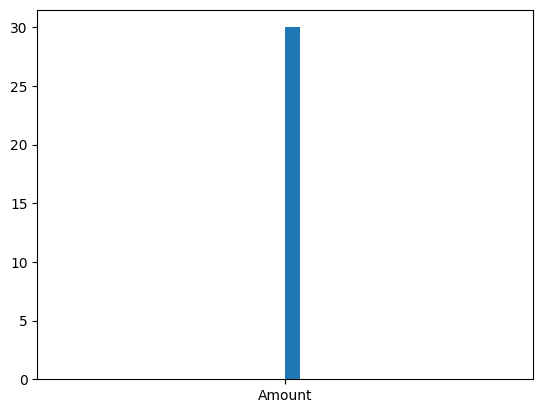

In [45]:
df=pd.read_csv(datapath)
df['Class'].value_counts()
df.isnull().sum().sum()
plt.hist(x='Amount',density=True,bins=30)
df['Amount'].skew()




array([[-1.3598071e+00, -7.2781175e-02,  2.5363467e+00, ...,
         1.3355838e-01, -2.1053053e-02,  5.0147600e+00],
       [ 1.1918571e+00,  2.6615071e-01,  1.6648011e-01, ...,
        -8.9830989e-03,  1.4724169e-02,  1.3056265e+00],
       [-1.3583541e+00, -1.3401631e+00,  1.7732093e+00, ...,
        -5.5352796e-02, -5.9751842e-02,  5.9392762e+00],
       ...,
       [ 1.9195650e+00, -3.0125386e-01, -3.2496397e+00, ...,
         4.4547720e-03, -2.6560828e-02,  4.2323661e+00],
       [-2.4044006e-01,  5.3048253e-01,  7.0251024e-01, ...,
         1.0882074e-01,  1.0453282e-01,  2.3978953e+00],
       [-5.3341252e-01, -1.8973334e-01,  7.0333737e-01, ...,
        -2.4153087e-03,  1.3648914e-02,  5.3844953e+00]],
      shape=(284807, 29), dtype=float32)

In [30]:
def data(path=datapath):
    df=pd.read_csv(path)
    y=df.pop('Class').to_numpy().astype(int)

    df['Amount']=np.log1p(df['Amount'])
    df=df.drop(columns=['Time'])
    X=df.to_numpy(dtype=np.float32)
    rng=np.random.default_rng(SEED)
    X_legit=X[y==0]
    X_legit=X_legit[rng.permutation(len(X_legit))]
    return X_legit,X[y==1],list(df.columns)



legit (284315, 29)  fraud (492, 29)  prevalence 0.1727%


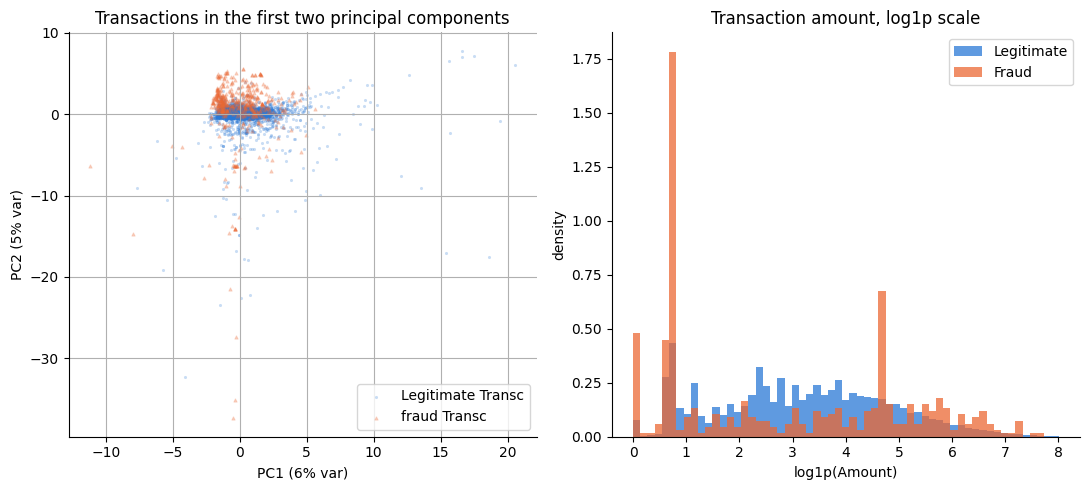

In [ ]:
Xl,Xf,COLS=data()
print(f"legit {Xl.shape}  fraud {Xf.shape}  prevalence {len(Xf)/(len(Xl)+len(Xf)):.4%}")
rng=np.random.default_rng(SEED)
sub=Xl[rng.choice(len(Xl),8000,replace=False)]
mu_,std_=sub.mean(axis=0),sub.std(axis=0)+1e-8
p=PCA(n_components=2,random_state=SEED).fit((sub-mu_)/std_)
Zl,Zf=p.transform((sub-mu_)/std_),p.transform((Xf-mu_)/std_)
fig,axes=plt.subplots(1,2,figsize=(11,5))
axes[0].scatter(*Zl.T,s=5,alpha=.25,lw=0,label='Legitimate Transc',c=C_LEGIT)
axes[0].scatter(*Zf.T,s=5,alpha=.25,lw=.8,marker='^',label='fraud Transc',c=C_FRAUD)
axes[0].set(title="Transactions in the first two principal components",
          xlabel=f"PC1 ({p.explained_variance_ratio_[0]:.0%} var)",
          ylabel=f"PC2 ({p.explained_variance_ratio_[1]:.0%} var)")
axes[0].grid(axis="both"); axes[0].legend(loc="best")

bins = np.linspace(0, np.log1p(3000), 60)
axes[1].hist(Xl[:, COLS.index("Amount")], bins=bins, density=True,
           color=C_LEGIT, alpha=.75, label="Legitimate")
axes[1].hist(Xf[:, COLS.index("Amount")], bins=bins, density=True,
           color=C_FRAUD, alpha=.75, label="Fraud")
axes[1].set(title="Transaction amount, log1p scale",
          xlabel="log1p(Amount)", ylabel="density")
axes[1].legend()
[f.spines[["top","right"]].set_visible(False) for f in fig.axes]
fig.tight_layout(); plt.show()





The KL itself is already self-correcting in both directions — as logvar $\to -\infty$ the $-\tfrac12\text{logvar}$ term blows up, and as logvar $\to +\infty$ the $-\tfrac12\exp(\text{logvar})$ term blows up — so the objective wants logvar near 0. The clamp isn't there to shape the objective; it's there to survive the first few hundred steps, when a randomly-initialized fc_logvar can emit something like 95 and exp overflows float32 to inf, which turns the whole batch to NaN permanently.

In [53]:
class VAE(nn.Module):
    def __init__(self,in_dim,hidden=(64,32),latent=4):
        super().__init__()

        enc,prev=[],in_dim
        for h in hidden:
            enc += [nn.Linear(prev,h),nn.SiLU()]
            prev=h
        self.enc=nn.Sequential(*enc)
        self.fc_mu=nn.Linear(prev,latent)
        self.fc_logvar=nn.Linear(prev,latent)

        dec,prev=[],latent
        for h in reversed(hidden):
            dec += [nn.Linear(prev,h),nn.SiLU()]
            prev=h
        self.dec=nn.Sequential(*dec)
        self.fc_out=nn.Linear(prev,in_dim)

        self.log_var_x=nn.Parameter(torch.zeros(1))

    def encode(self,x):
        h=self.enc(x)
        return self.fc_mu(h),self.fc_logvar(h).clamp(-8.0,8.0) #(e^-8,e^8)

    def decode(self,z):
        return self.fc_out(self.dec(z))

    def forward(self,x):
        mu,logvar=self.encode(x)
        z=mu + torch.exp(0.5*logvar) * torch.randn_like(mu) #reparamterization
        return self.decode(z),mu,logvar




In [ ]:
# LOG2PI=np.log(2 *np.pi)
LOG2PI=math.log(2 * math.pi) #faster for single scalar than numpy 

def elbo_loss(x,x_hat,mu,logvar,log_var_x,beta=1.0):
    """ ELBO loss = reconstruction loss + beta  * KL (q(z|x)||p(z)) returns averaged elbo loss, nll , kl"""
    nll= 0.5*(((x-x_hat)**2)/log_var_x.exp() + LOG2PI + log_var_x).sum(1) #(B,)
    kl=-0.5 * (1 + logvar - mu**2 - logvar.exp()).sum(1) #(B,)
    return (nll + beta * kl ).mean(),nll.mean().item(),kl.mean().item()

In [59]:
@torch.no_grad()
def neg_log_likelihood(model,x,L=64):
    """IWAE bound with L posterior samples. Lower is more normal """
    mu,logvar=model.encode(x) #(B,K)
    std=torch.exp(0.5*logvar)
    eps=torch.randn(L,*mu.shape,device=x.device)
    z= mu + std * eps
    B,K=z.shape

    x_hat=model.decode(z.reshape(L*B,K)).reshape(L,B,-1)
    lv=model.log_var_x

    log_p_x_z = -0.5 * (((x - x_hat) ** 2) / lv.exp() + lv + LOG2PI).sum(-1)  # log p(x|z)
    log_p_z = -0.5 * (z ** 2 + LOG2PI).sum(-1) # log p(z)
    log_q_z = -0.5 * (eps ** 2 + logvar + LOG2PI).sum(-1) #log_p_x_z + log_p_z - log_q_z

    log_w=log_p_x_z+ log_p_z-log_q_z # (L,B)
    return-(torch.logsumexp(log_w,0)-math.log(L)) #(B,)

@torch.no_grad()
def score_all(model,X,batch=1024,L=64):
    model.eval()
    return torch.cat([neg_log_likelihood(model,X[i:i+batch].to(DEVICE),L).cpu() for i in range(0,len(X),batch)])


def auc(scores,labels):
    order=np.argsort(scores)
    ranks=np.empty_like(order,dtype=float)
    ranks[order]=np.arange(1,len(scores)+1)
    n_pos, n_neg = labels.sum(), (1 - labels).sum()
    return (ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)






In [ ]:
def train_vae(epochs=40,warmup=8,hidden=(64,128),latent=12,lr=1e-3,batch=512,patience_max=8,diag_n=400,dataI=None):
    """training loop for vae"""

    X_legit,X_fraud,cols= data() if dataI is None else dataI
    D=X_legit.shape[1]

    n_tr,n_va=int(.7 * len(X_legit)),int(.15 * len(X_legit))
    tr_r,va_r=X_legit[:n_tr],X_legit[n_tr:n_tr+n_va]
    te_r=X_legit[n_tr+n_va:]

    mu_,std_=tr_r.mean(0),tr_r.std(0)+1e-8
    z= lambda a : torch.from_numpy((a-mu_)/(std_))
    tr, va, te_n, te_a = z(tr_r), z(va_r), z(te_r), z(X_fraud)
    print(f"train {len(tr)} | val {len(va)} | test-legit {len(te_n)} | test-fraud {len(te_a)}")
    print(f"{len(tr)//batch + 1} steps/epoch -> {(len(tr)//batch + 1)*epochs} total updates")

    loader=DataLoader(TensorDataset(tr),batch_size=batch,shuffle=True)
    model=VAE(D,hidden,latent).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr)
    